<a href="https://colab.research.google.com/github/sureshbendaab40/PYTHON_INTERNSHIP/blob/main/Suresh_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#data load kar rhe hai
import numpy as np, matplotlib.pyplot as plt
from tensorflow import keras
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
names = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
print(x_train.shape, x_test.shape)





29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28) (10000, 28, 28)


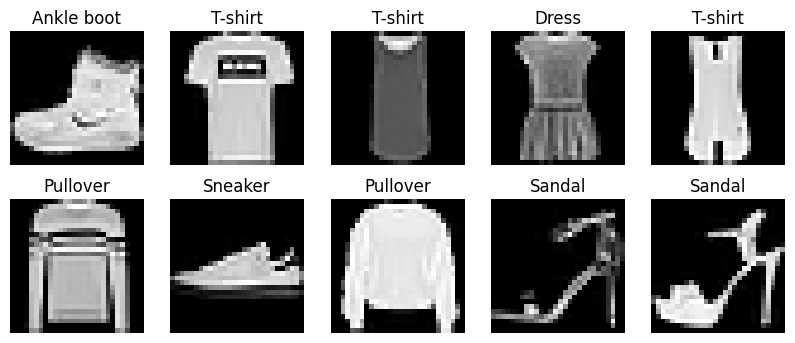

In [2]:
#sample Images dhekege
plt.figure(figsize=(10,4))
for i in range(10): #kam images ke liye
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(names[y_train[i]]); plt.axis('off')
plt.show()

In [3]:
#Traditional model (Random Forest)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
xtr = x_train.reshape(len(x_train), -1)/255.0
xte = x_test.reshape(len(x_test), -1)/255.0
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(xtr[:20000], y_train[:20000])
rf_acc = accuracy_score(y_test, rf.predict(xte))
print("Random Forest accuracy:", rf_acc)


Random Forest accuracy: 0.8621


In [4]:
#CNN banao trainned
xtr_c = x_train.reshape(-1,28,28,1)/255.0
xte_c = x_test.reshape(-1,28,28,1)/255.0
model = keras.Sequential([
    keras.layers.Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    keras.layers.MaxPooling2D(2),
    keras.layers.Conv2D(64,(3,3),activation='relu'),
    keras.layers.MaxPooling2D(2),
    keras.layers.Flatten(),
    keras.layers.Dense(128,activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10,activation='softmax')])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
history = model.fit(xtr_c, y_train, epochs=8, validation_split=0.1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - accuracy: 0.8168 - loss: 0.5019 - val_accuracy: 0.8740 - val_loss: 0.3345
Epoch 2/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8791 - loss: 0.3317 - val_accuracy: 0.8823 - val_loss: 0.3047
Epoch 3/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8934 - loss: 0.2909 - val_accuracy: 0.9005 - val_loss: 0.2599
Epoch 4/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9067 - loss: 0.2575 - val_accuracy: 0.9060 - val_loss: 0.2538
Epoch 5/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9125 - loss: 0.2356 - val_accuracy: 0.9047 - val_loss: 0.2690
Epoch 6/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9193 - loss: 0.2163 - val_accuracy: 0.9185 - val_loss: 0.2306
Epoch 7/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9264 - loss: 0.1975 - val_accuracy: 0.9142 - val_loss: 0.2339
Epoch 8/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9299 - loss: 0.1845 - val_acc

In [5]:
#comparing the models
cnn_loss, cnn_acc = model.evaluate(xte_c, y_test)
print("Random Forest:", rf_acc)
print("CNN:", cnn_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9060 - loss: 0.2521
Random Forest: 0.8621
CNN: 0.906000018119812


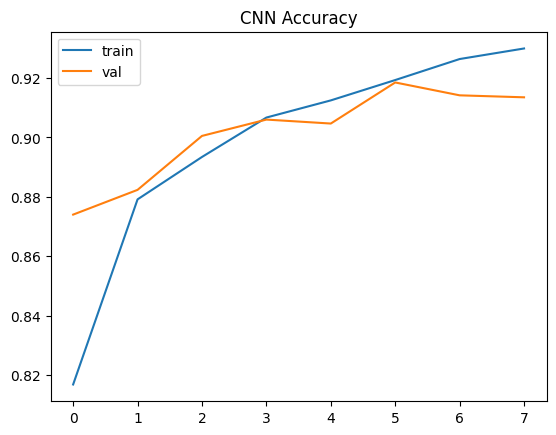

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


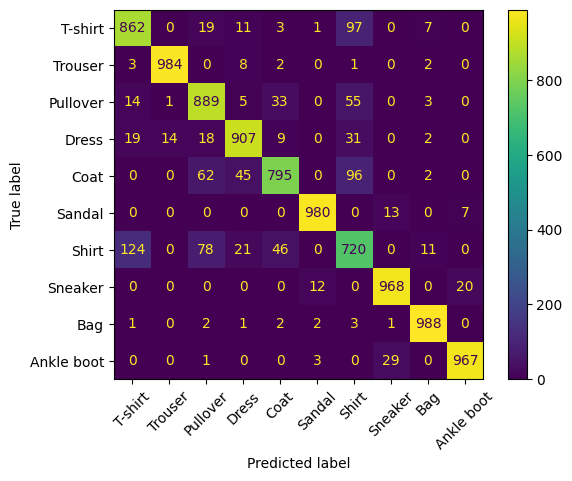

In [6]:
#Graph + Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('CNN Accuracy'); plt.show()

pred = np.argmax(model.predict(xte_c), axis=1)
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=names).plot(xticks_rotation=45)
plt.show()
